#Bootstrap Analysis

This notebook uses Bootstrap resampling to evaluate the credit card default dataset.

Import libraries needed for data manipulation, numericla calculations, and visualization.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# Upload the cleaned dataset created in the data cleaning notebook.
#Data file to use: cleaned_credit_card_data.csv
from google.colab import files
uploaded = files.upload()

Saving cleaned_credit_card_data.csv to cleaned_credit_card_data.csv


In [3]:
# Load the cleaned dataset into a pandas DataFrame.
df = pd.read_csv("cleaned_credit_card_data.csv")

# Display the first five observations to verify that
# the dataset loaded correctly.
df.head()

# Verify the dataset before beginning the bootstrap analysis.
print(f"Number of Customer Observations: {df.shape[0]:,}")
print(f"Number of Variables: {df.shape[1]}")
print(f"Total Missing Values: {df.isnull().sum().sum()}")

# Display the unique values in the target variable.
target_values = sorted(df["DEFAULT"].unique().tolist())
print(f"Target Variable Values: {target_values}")

Number of Customer Observations: 30,000
Number of Variables: 24
Total Missing Values: 0
Target Variable Values: [0, 1]


In [4]:
## 4. Calculate the Original Default Rate

# Calculate the proportion of customers who defaulted.
# Since DEFAULT is coded as 0 and 1, the mean represents
# the proportion of customers with DEFAULT = 1.
original_default_rate = df["DEFAULT"].mean()

# Display the default rate and percentage.
print(f"Original Default Rate: {original_default_rate:.4f}")
print(f"Original Default Percentage: {original_default_rate * 100:.2f}%")

Original Default Rate: 0.2212
Original Default Percentage: 22.12%


In [5]:
## 5. Generate Bootstrap Samples

# Set the number of bootstrap samples.
n_bootstrap = 1000

# Create an empty list to store the default rate
# calculated from each bootstrap sample.
bootstrap_default_rates = []

# Set a random seed so the results can be reproduced.
np.random.seed(42)

# Generate 1,000 bootstrap samples.
for i in range(n_bootstrap):
    # Sample 30,000 customers with replacement.
    bootstrap_sample = df.sample(
        n=len(df),
        replace=True
    )
    # Calculate the default rate for the bootstrap sample.
    bootstrap_rate = bootstrap_sample["DEFAULT"].mean()
    # Store the result.
    bootstrap_default_rates.append(bootstrap_rate)

# Convert the results to a NumPy array for later calculations.
bootstrap_default_rates = np.array(bootstrap_default_rates)
print(f"Number of Bootstrap Samples: {len(bootstrap_default_rates):,}")
print(f"Mean Bootstrap Default Rate: {bootstrap_default_rates.mean():.4f}")

Number of Bootstrap Samples: 1,000
Mean Bootstrap Default Rate: 0.2212


In [6]:
## 6. Calculate Bootstrap Standard Error and Confidence Interval

# Calculate the standard deviation of the bootstrap default rates.
# This provides an estimate of the standard error of the default rate.
bootstrap_standard_error = np.std(
    bootstrap_default_rates,
    ddof=1
)

# Calculate the 95% bootstrap confidence interval using
# the 2.5th and 97.5th percentiles of the bootstrap distribution.
lower_bound = np.percentile(
    bootstrap_default_rates,
    2.5
)
upper_bound = np.percentile(
    bootstrap_default_rates,
    97.5
)

# Display the bootstrap standard error and confidence interval.
print(f"Bootstrap Standard Error: {bootstrap_standard_error:.4f}")
print(f"95% Bootstrap Confidence Interval: {lower_bound:.4f} to {upper_bound:.4f}")

Bootstrap Standard Error: 0.0023
95% Bootstrap Confidence Interval: 0.2168 to 0.2257


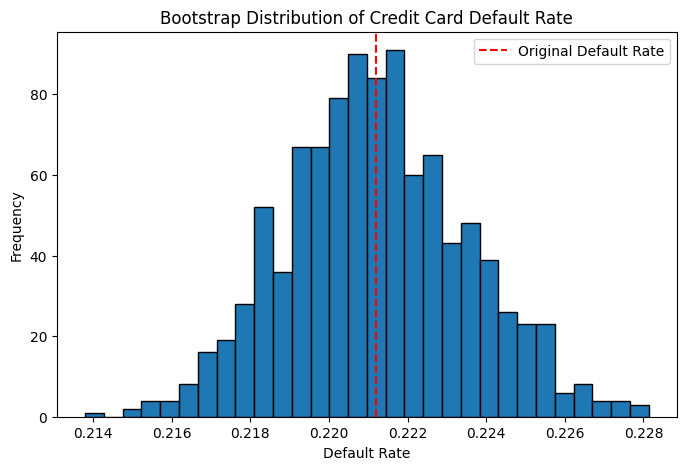

In [9]:
## 7. Visualize the Bootstrap Distribution

# Create a histogram showing the distribution of the
# default rates obtained from the 1,000 bootstrap samples.
plt.figure(figsize=(8, 5))
plt.hist(
    bootstrap_default_rates,
    bins=30,
    edgecolor="black"
)
# Add a vertical line showing the original default rate.
plt.axvline(
    original_default_rate,
    color="red",
    linestyle="--",
    label="Original Default Rate"
)

plt.title("Bootstrap Distribution of Credit Card Default Rate")
plt.xlabel("Default Rate")
plt.ylabel("Frequency")
plt.legend()
plt.show()

## 8. Bootstrap Results Interpretation

The original credit card default rate was 22.12%. After generating 1,000 bootstrap samples, the mean bootstrap default rate was also approximately 22.12%, showing that the bootstrap estimates were centered around the original sample estimate.

The bootstrap standard error was 0.0023, showing relatively low variability in the estimated default rate. The 95% bootstrap confidence interval ranged from 21.68% to 22.57%. This provides a range of plausible values for the population default rate based on the bootstrap analysis.

The histogram also shows that the bootstrap default rates form an approximately bell-shaped distribution centered near the original default rate.

In [8]:
## 9. Bootstrap Key Numerical Variables

# Select the numerical variables that showed stronger differences
# between customers who defaulted and those who did not.
key_numerical_variables = [
    "LIMIT_BAL",
    "PAY_AMT1",
    "PAY_AMT2",
    "PAY_AMT3",
    "PAY_AMT4",
    "PAY_AMT5",
    "PAY_AMT6"
]

# Create an empty list to store the bootstrap results.
variable_bootstrap_results = []

# Set the random seed so the results can be reproduced.
np.random.seed(42)

# Analyze each selected numerical variable.
for variable in key_numerical_variables:
    # Create an empty list to store the mean differences.
    bootstrap_differences = []
    # Generate 1,000 bootstrap samples.
    for i in range(n_bootstrap):
        # Sample 30,000 customers with replacement.
        bootstrap_sample = df.sample(
            n=len(df),
            replace=True
        )
        # Separate customers who did not default.
        no_default_values = bootstrap_sample.loc[
            bootstrap_sample["DEFAULT"] == 0,
            variable
        ]
        # Separate customers who defaulted.
        default_values = bootstrap_sample.loc[
            bootstrap_sample["DEFAULT"] == 1,
            variable
        ]

        # Calculate the mean for each group.
        no_default_mean = np.mean(no_default_values)
        default_mean = np.mean(default_values)
        # Calculate the difference between the two groups.
        mean_difference = no_default_mean - default_mean
        # Store the mean difference.
        bootstrap_differences.append(mean_difference)

    # Calculate the 95% bootstrap confidence interval.
    lower_bound = np.percentile(
        bootstrap_differences,
        2.5
    )
    upper_bound = np.percentile(
        bootstrap_differences,
        97.5
    )
    # Store the results for each variable.
    variable_bootstrap_results.append({
        "Variable": variable,
        "Mean Difference": np.mean(bootstrap_differences),
        "95% CI Lower": lower_bound,
        "95% CI Upper": upper_bound
    })

# Convert the results into a DataFrame.
bootstrap_variable_summary = pd.DataFrame(
    variable_bootstrap_results
)

# Display the bootstrap results using f-string formatting.
for result in variable_bootstrap_results:

    print(f"Variable: {result['Variable']}")
    print(f"Mean Difference: {result['Mean Difference']:,.2f}")
    print(f"95% CI Lower: {result['95% CI Lower']:,.2f}")
    print(f"95% CI Upper: {result['95% CI Upper']:,.2f}")
    print()

Variable: LIMIT_BAL
Mean Difference: 48,019.91
95% CI Lower: 44,888.70
95% CI Upper: 51,132.62

Variable: PAY_AMT1
Mean Difference: 2,905.93
95% CI Lower: 2,573.91
95% CI Upper: 3,237.67

Variable: PAY_AMT2
Mean Difference: 3,246.56
95% CI Lower: 2,824.76
95% CI Upper: 3,670.91

Variable: PAY_AMT3
Mean Difference: 2,383.04
95% CI Lower: 1,971.41
95% CI Upper: 2,767.96

Variable: PAY_AMT4
Mean Difference: 2,153.72
95% CI Lower: 1,827.82
95% CI Upper: 2,478.46

Variable: PAY_AMT5
Mean Difference: 2,036.92
95% CI Lower: 1,674.42
95% CI Upper: 2,383.95

Variable: PAY_AMT6
Mean Difference: 2,280.19
95% CI Lower: 1,853.97
95% CI Upper: 2,681.43



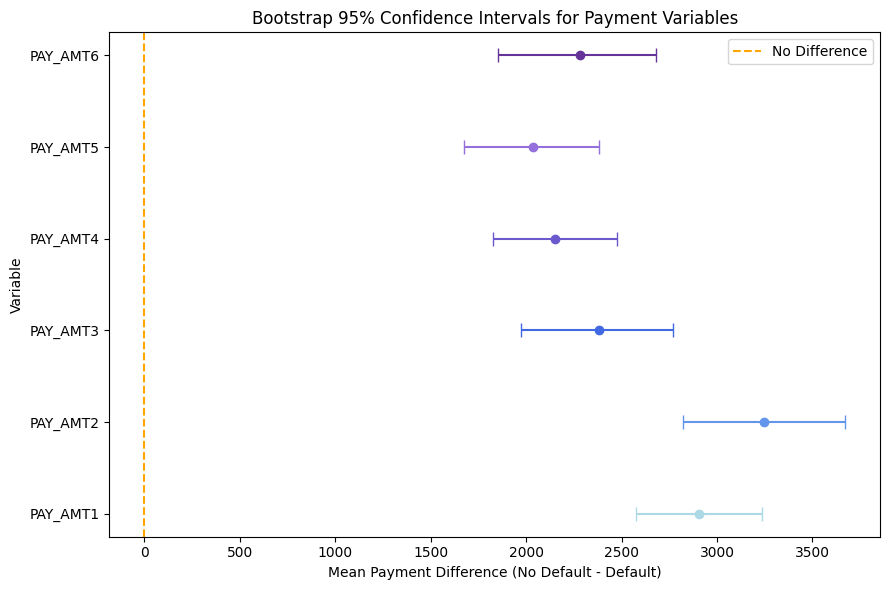

In [22]:
## 10. Visualize Bootstrap Confidence Intervals

# Select the payment variables for visualization.
payment_results = bootstrap_variable_summary[
    bootstrap_variable_summary["Variable"] != "LIMIT_BAL"
]

# Create colors for each payment variable.
colors = [
    "lightblue",
    "cornflowerblue",
    "royalblue",
    "slateblue",
    "mediumpurple",
    "rebeccapurple"
]
# Create a confidence interval plot for the payment variables.
plt.figure(figsize=(9, 6))

# Plot each payment variable with a different color.
for i, (_, row) in enumerate(payment_results.iterrows()):
    plt.errorbar(
        row["Mean Difference"],
        row["Variable"],
        xerr=[
            [row["Mean Difference"] - row["95% CI Lower"]],
            [row["95% CI Upper"] - row["Mean Difference"]]
        ],
        fmt="o",
        capsize=5,
        color=colors[i]
    )

# Add a vertical line at zero to represent no difference.
plt.axvline(
    0,
    color="orange",
    linestyle="--",
    label="No Difference"
)

# Add graph labels and title.
plt.title("Bootstrap 95% Confidence Intervals for Payment Variables")
plt.xlabel("Mean Payment Difference (No Default - Default)")
plt.ylabel("Variable")
plt.legend()
plt.tight_layout()
plt.show()

Reference:

GeeksforGeeks. (2025, July 12). Matplotlib.pyplot.errorbar() in Python. GeeksforGeeks.  ⁠https://www.geeksforgeeks.org/python/matplotlib-pyplot-errorbar-in-python/

## 11. Connection to Variable Analysis

The previous variable analysis found that LIMIT_BAL and the PAY_AMT variables had statistically significant differences between customers who defaulted and customers who did not default. Bootstrap resampling was used to further examine how stable these differences were across repeated samples.

The bootstrap results supported the previous findings. LIMIT_BAL showed an average difference of approximately $48,020 between the non-default and default groups, with a 95% bootstrap confidence interval from approximately $44,889 to $51,133. The PAY_AMT1 through PAY_AMT6 variables also had positive mean differences, and none of their 95% bootstrap confidence intervals included zero. This can also be seen in the confidence interval graph, where all of the PAY_AMT confidence intervals remain above the zero-difference line.

These results suggest that the differences found during the variable analysis were relatively stable across the bootstrap samples. Customers who did not default generally had higher credit limits and higher previous payment amounts than customers who defaulted. These variables can now be compared with the results of the Decision Tree model to determine whether they are also useful for predicting default.